In [1]:
import os
import random
from pathlib import Path
from PIL import Image
import xml.etree.ElementTree as ET

import cv2
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt 
from tqdm import tqdm

%matplotlib inline

In [4]:
images_path = Path(r'D:\Self Study\Coding\Projects\Stanford-Dogs\data\raw\images\Images')
images_per_class = {}
print("Number of Classes: ", len(os.listdir(images_path)))
for dir in images_path.iterdir():
    images_per_class.update({dir.stem : len(os.listdir(dir))})

print("Number of images_per_class", images_per_class)

Number of Classes:  120
Number of images_per_class {'n02085620-Chihuahua': 152, 'n02085782-Japanese_spaniel': 185, 'n02085936-Maltese_dog': 252, 'n02086079-Pekinese': 149, 'n02086240-Shih-Tzu': 214, 'n02086646-Blenheim_spaniel': 188, 'n02086910-papillon': 196, 'n02087046-toy_terrier': 172, 'n02087394-Rhodesian_ridgeback': 172, 'n02088094-Afghan_hound': 239, 'n02088238-basset': 175, 'n02088364-beagle': 195, 'n02088466-bloodhound': 187, 'n02088632-bluetick': 171, 'n02089078-black-and-tan_coonhound': 159, 'n02089867-Walker_hound': 153, 'n02089973-English_foxhound': 157, 'n02090379-redbone': 148, 'n02090622-borzoi': 151, 'n02090721-Irish_wolfhound': 218, 'n02091032-Italian_greyhound': 182, 'n02091134-whippet': 187, 'n02091244-Ibizan_hound': 188, 'n02091467-Norwegian_elkhound': 196, 'n02091635-otterhound': 151, 'n02091831-Saluki': 200, 'n02092002-Scottish_deerhound': 232, 'n02092339-Weimaraner': 160, 'n02093256-Staffordshire_bullterrier': 155, 'n02093428-American_Staffordshire_terrier': 164

Text(0, 0.5, '# Images')

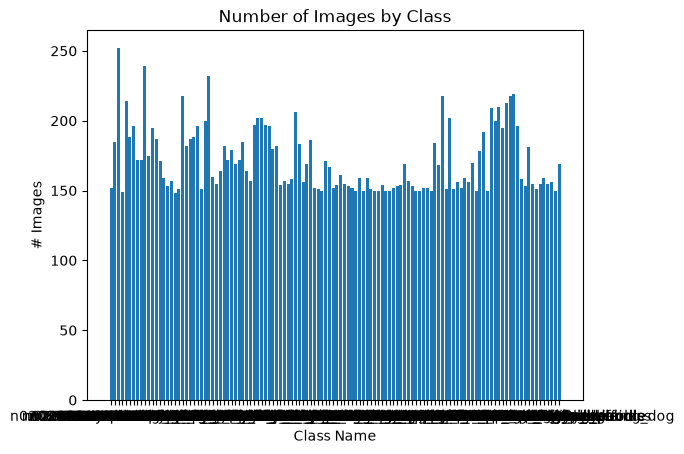

In [16]:
plt.bar(images_per_class.keys(), images_per_class.values())
plt.title("Number of Images by Class")
plt.xlabel('Class Name')
plt.ylabel('# Images')

d:\Self Study\Coding\Projects\Stanford-Dogs\.venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:601: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=self.figsize)


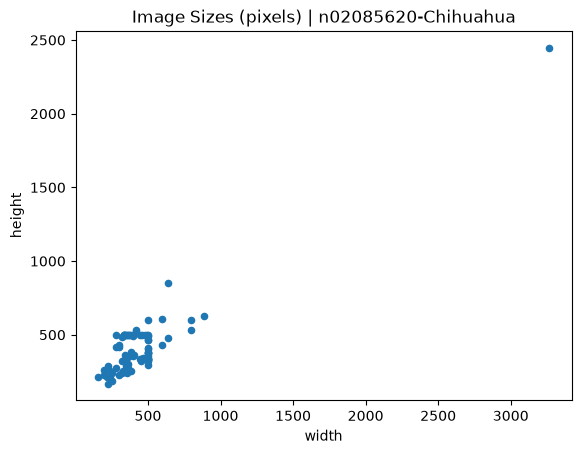

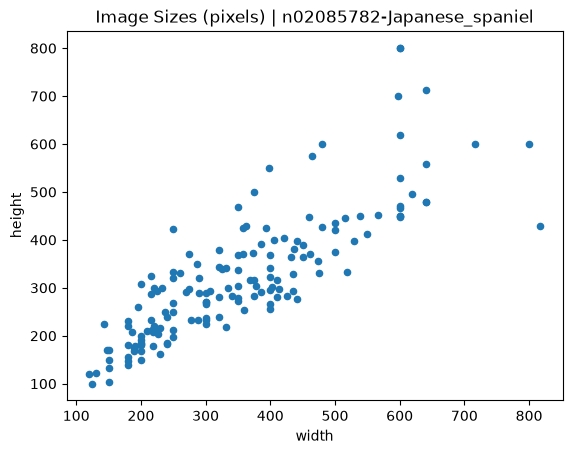

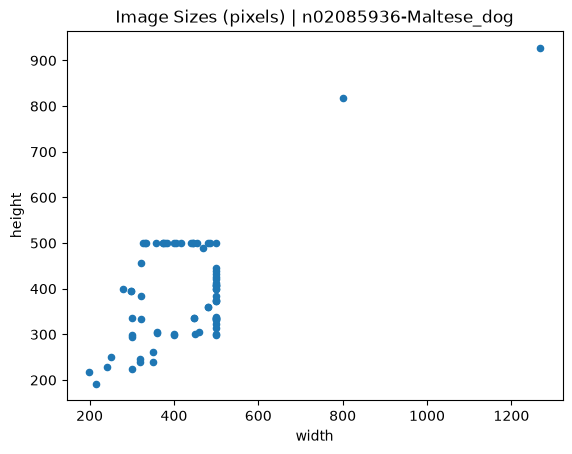

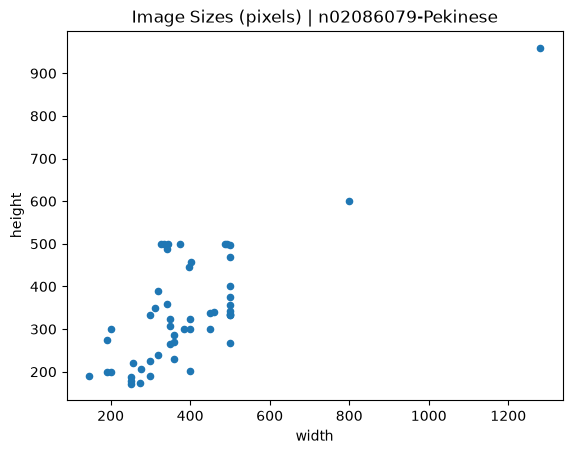

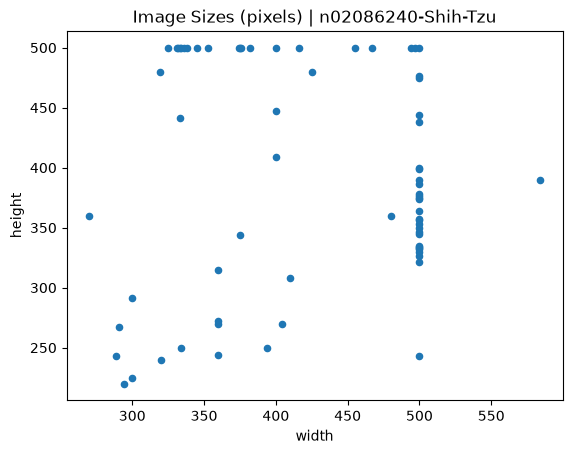

...

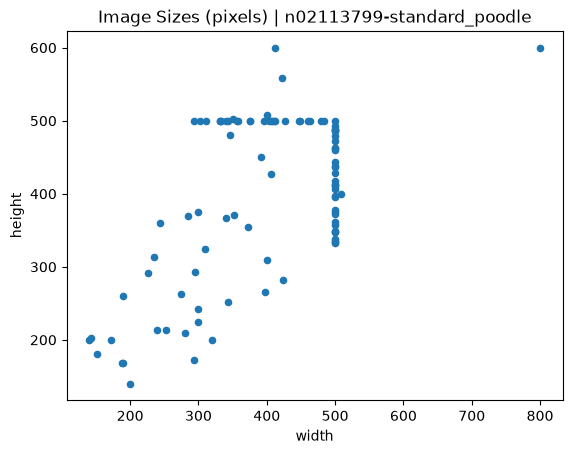

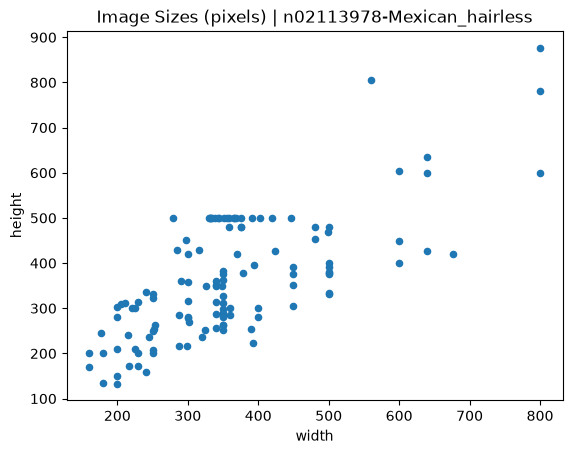

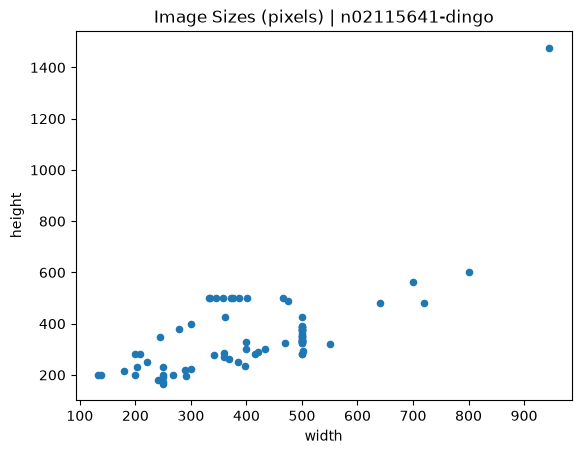

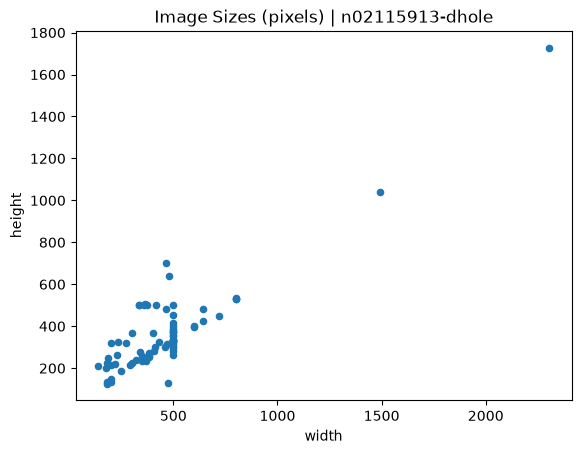

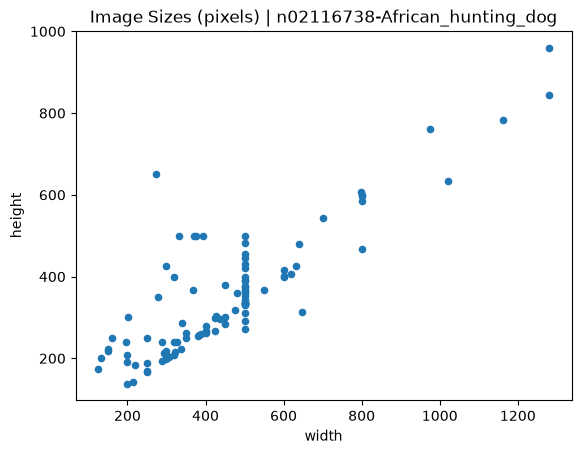

In [17]:
for dir in images_path.iterdir():
    images_per_dir = []
    for image in dir.iterdir():
        with Image.open(image) as img:
            images_per_dir.append([img.height, img.width])
    dim_df = pd.DataFrame(images_per_dir, columns=['height', 'width'])
    sizes = dim_df.groupby(['height', 'width']).size().reset_index().rename(columns={0:'count'})
    sizes.plot.scatter(x='width', y='height');
    plt.title('Image Sizes (pixels) | {}'.format(dir.stem))

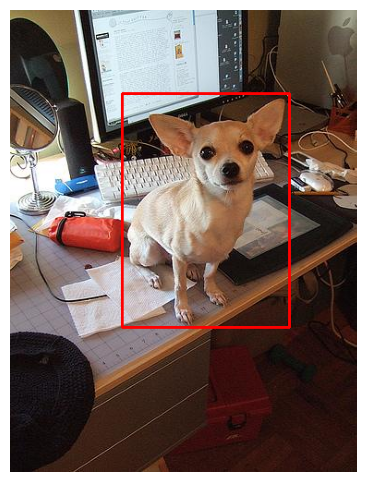

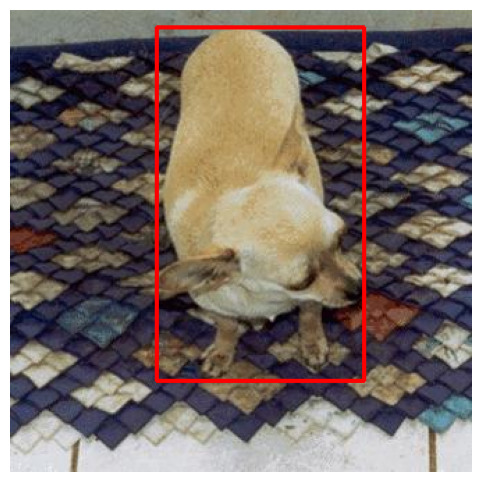

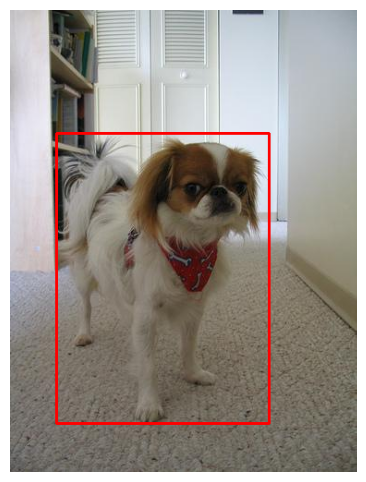

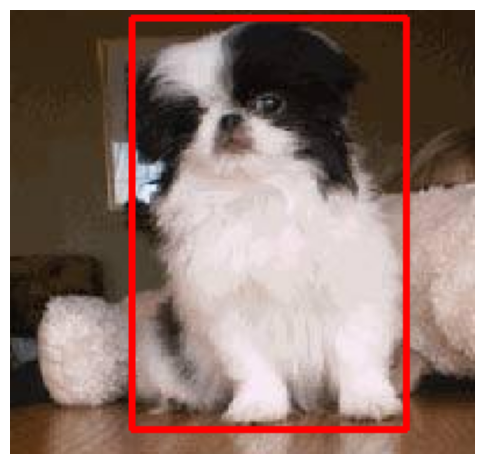

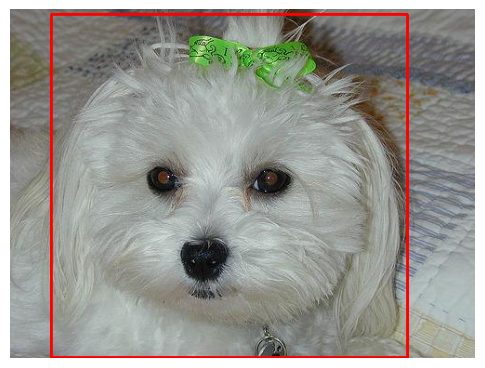

...

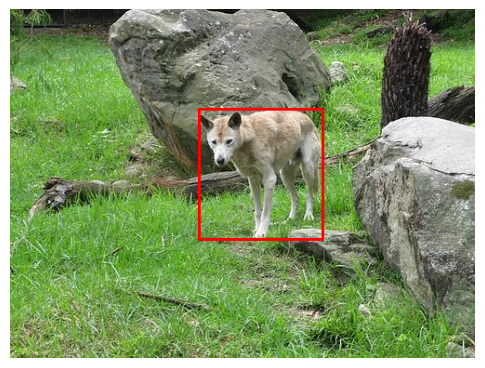

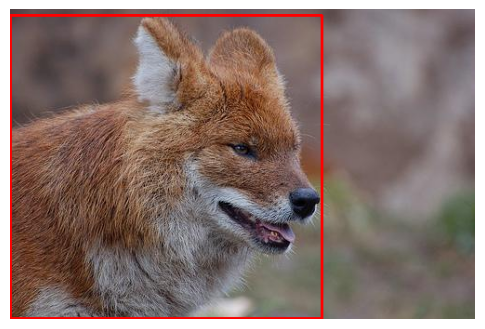

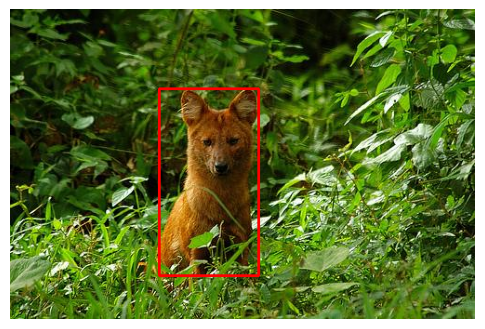

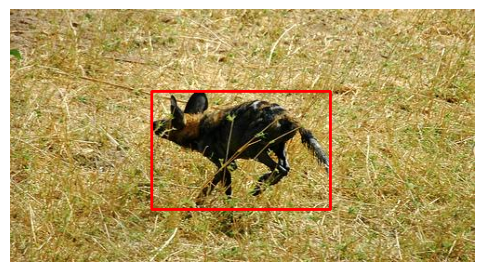

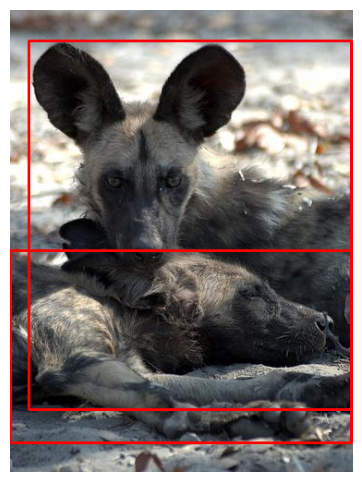

In [38]:
for dir in images_path.iterdir():
    random_images = random.sample(os.listdir(dir), 2)
    random_images = [os.path.join(dir,img) for img in random_images]

    for img in random_images:
        annot = annot_path = Path(img.replace("Images", "Annotation").replace("images", "annotations")).with_suffix("")
        image = cv2.imread(img)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        tree = ET.parse(annot)
        root = tree.getroot()

        for obj in root.findall("object"):

            bndbox = obj.find("bndbox")
            xmin = int(bndbox.find("xmin").text)
            ymin = int(bndbox.find("ymin").text)
            xmax = int(bndbox.find("xmax").text)
            ymax = int(bndbox.find("ymax").text)

            width = xmax - xmin
            height = ymax - ymin

            cv2.rectangle(image, (xmin, ymin), (xmax, ymax), (255, 0, 0), 2)

        plt.figure(figsize=(6, 6))
        plt.imshow(image)
        plt.axis("off")
        plt.show()
        plt.close()

### SETUP PATHS

In [2]:
DATA_DIR =  Path(r"D:\Self Study\Coding\Projects\Stanford-Dogs\data\raw")
IMAGES_DIR = DATA_DIR / r"images\Images"
ANNOTATIONS_DIR = DATA_DIR / r"annotations/Annotation"

## ASPECT RATIO & BOUNDING BOX AREA ANALYSIS

Extracting spatial & bounding box metrics...


  0%|          | 0/120 [00:00<?, ?it/s]

100%|██████████| 120/120 [06:27<00:00,  3.23s/it]


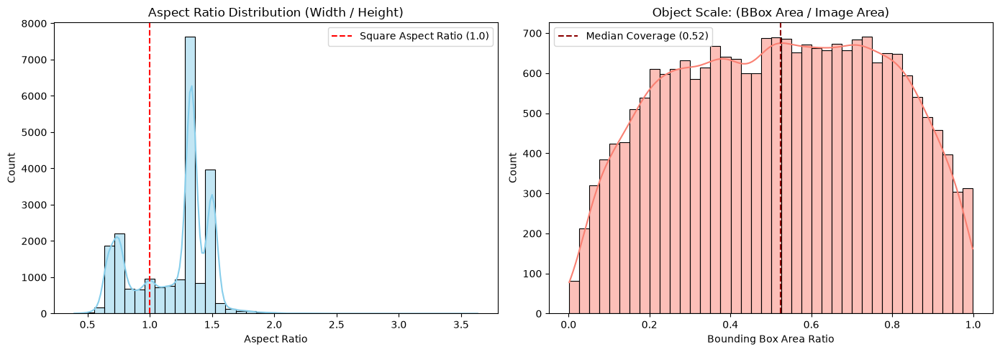

Median Aspect Ratio: 1.33
Median Object Coverage: 52.5% of image area


In [3]:
records = []

print("Extracting spatial & bounding box metrics...")
for breed_dir in tqdm(list(IMAGES_DIR.iterdir())):
    if not breed_dir.is_dir():
        continue

    breed_name = breed_dir.name.split("-")[-1]

    for img_path in breed_dir.glob("*.jpg"):
        # Match annotation file (same subfolder structure, extensionless)
        annot_path = (
            ANNOTATIONS_DIR / img_path.parent.name / img_path.stem
        )

        try:
            with Image.open(img_path) as img:
                img_w, img_h = img.size

            aspect_ratio = img_w / img_h
            img_area = img_w * img_h

            # Parse Bounding Box from XML
            if annot_path.exists():
                tree = ET.parse(annot_path)
                root = tree.getroot()

                for obj in root.findall("object"):
                    bndbox = obj.find("bndbox")
                    xmin = float(bndbox.find("xmin").text)
                    ymin = float(bndbox.find("ymin").text)
                    xmax = float(bndbox.find("xmax").text)
                    ymax = float(bndbox.find("ymax").text)

                    bbox_w = xmax - xmin
                    bbox_h = ymax - ymin
                    bbox_area = bbox_w * bbox_h
                    bbox_coverage = bbox_area / img_area

                    records.append(
                        {
                            "breed": breed_name,
                            "image_path": str(img_path),
                            "width": img_w,
                            "height": img_h,
                            "aspect_ratio": aspect_ratio,
                            "bbox_coverage": bbox_coverage,
                        }
                    )
        except Exception as e:
            continue

df_metrics = pd.DataFrame(records)

# --- PLOTTING SPATIAL METRICS ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Aspect Ratio Distribution
sns.histplot(
    df_metrics["aspect_ratio"], bins=40, kde=True, ax=axes[0], color="skyblue"
)
axes[0].axvline(
    1.0, color="red", linestyle="--", label="Square Aspect Ratio (1.0)"
)
axes[0].set_title("Aspect Ratio Distribution (Width / Height)")
axes[0].set_xlabel("Aspect Ratio")
axes[0].set_ylabel("Count")
axes[0].legend()

# Plot 2: Bounding Box Area Coverage Ratio
sns.histplot(
    df_metrics["bbox_coverage"], bins=40, kde=True, ax=axes[1], color="salmon"
)
axes[1].axvline(
    df_metrics["bbox_coverage"].median(),
    color="darkred",
    linestyle="--",
    label=f"Median Coverage ({df_metrics['bbox_coverage'].median():.2f})",
)
axes[1].set_title("Object Scale: (BBox Area / Image Area)")
axes[1].set_xlabel("Bounding Box Area Ratio")
axes[1].set_ylabel("Count")
axes[1].legend()

plt.tight_layout()
plt.show()

print(
    f"Median Aspect Ratio: {df_metrics['aspect_ratio'].median():.2f}"
)
print(
    f"Median Object Coverage: {df_metrics['bbox_coverage'].median() * 100:.1f}% of image area"
)

- From the aspect ratio distribution, basic resize won't be good, we will use RandomResizedCrop
- From the bounding box area Ratio, we know that cropping and using the bounding box is essential, also if we randomresizecrop the scale cannot be less than 0.35 (The number choice is done by gemini, we try no avoid getting crops that are all background)

## GLOBAL PIXEL INTENSITY, CHANNEL STATS & HSV ANALYSIS



Calculating RGB Mean/Std and HSV Brightness/Saturation...


100%|██████████| 20580/20580 [03:04<00:00, 111.75it/s]



--- DATASET RGB CHANNEL METRICS ---
Calculated Dataset Mean [R, G, B]: [0.474, 0.45, 0.39]
Calculated Dataset Std  [R, G, B]: [0.264, 0.258, 0.263]
Standard ImageNet Mean  [R, G, B]: [0.485, 0.456, 0.406]
Standard ImageNet Std   [R, G, B]: [0.229, 0.224, 0.225]


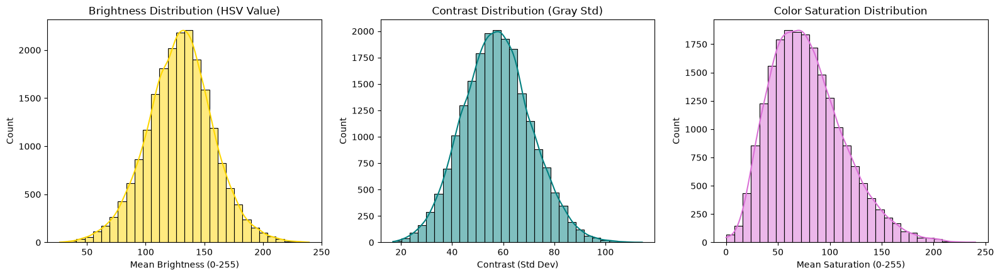

In [4]:
print("\nCalculating RGB Mean/Std and HSV Brightness/Saturation...")

# Running accumulators for Welford's algorithm / global RGB channel stats
channel_sum = np.zeros(3, dtype=np.float64)
channel_sum_sq = np.zeros(3, dtype=np.float64)
total_pixel_count = 0

brightness_list = []
contrast_list = []
saturation_list = []

all_image_paths = list(IMAGES_DIR.rglob("*.jpg"))

for img_path in tqdm(all_image_paths):
    # Read image using OpenCV
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        continue

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    # Scale RGB values to [0, 1] for PyTorch compatibility
    img_rgb_norm = img_rgb.astype(np.float32) / 255.0

    # 1. Update Global RGB Mean and Standard Deviation counters
    num_pixels = img_rgb_norm.shape[0] * img_rgb_norm.shape[1]
    total_pixel_count += num_pixels

    channel_sum += img_rgb_norm.sum(axis=(0, 1))
    channel_sum_sq += (img_rgb_norm**2).sum(axis=(0, 1))

    # 2. HSV & Grayscale Statistics
    img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # Brightness = Mean of V (Value) channel
    brightness_list.append(img_hsv[:, :, 2].mean())
    # Saturation = Mean of S (Saturation) channel
    saturation_list.append(img_hsv[:, :, 1].mean())
    # Contrast = Standard Deviation of Grayscale channel
    contrast_list.append(img_gray.std())

# Calculate final dataset-level RGB Mean and Std
rgb_mean = channel_sum / total_pixel_count
rgb_std = np.sqrt((channel_sum_sq / total_pixel_count) - (rgb_mean**2))

print("\n--- DATASET RGB CHANNEL METRICS ---")
print(f"Calculated Dataset Mean [R, G, B]: {np.round(rgb_mean, 3).tolist()}")
print(f"Calculated Dataset Std  [R, G, B]: {np.round(rgb_std, 3).tolist()}")
print(f"Standard ImageNet Mean  [R, G, B]: [0.485, 0.456, 0.406]")
print(f"Standard ImageNet Std   [R, G, B]: [0.229, 0.224, 0.225]")

# --- PLOTTING HSV & BRIGHTNESS METRICS ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(brightness_list, bins=30, kde=True, ax=axes[0], color="gold")
axes[0].set_title("Brightness Distribution (HSV Value)")
axes[0].set_xlabel("Mean Brightness (0-255)")

sns.histplot(contrast_list, bins=30, kde=True, ax=axes[1], color="teal")
axes[1].set_title("Contrast Distribution (Gray Std)")
axes[1].set_xlabel("Contrast (Std Dev)")

sns.histplot(saturation_list, bins=30, kde=True, ax=axes[2], color="orchid")
axes[2].set_title("Color Saturation Distribution")
axes[2].set_xlabel("Mean Saturation (0-255)")

plt.tight_layout()
plt.show()

WE only need to apply mild ColorJitter:
transforms.ColorJitter(
    brightness=0.15,
    contrast=0.15,
    saturation=0.15,
    hue=0.05
)